# Our model was coming up 100% accuracte everytime

We had a leak...

I ran a numerical logistical model and it was still 100% accurate. Meaning the leak was in the numerical data.

## Tests to investigate the leak:

In [3]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

df_text = pd.read_csv("../created_data/df_text.csv")

numerical_features = [
    "word_count",
    "char_count",
    "complexity_score",
    "unique_word_count",
    "sentence_count",
    "avg_sentence_length",
    "unique_word_ratio",
    "avg_word_length",
    "long_word_ratio",
    "short_word_ratio",
    "punctuation_count",
    "punctuation_ratio",
    "sentence_length_std",
    "word_length_std",
    "commonword_ratio"
]

for col in numerical_features:
    print("\n", col)
    print(
        df_text.groupby("label")[col]
          .describe()[["mean", "std", "min", "max"]]
    )


 word_count
            mean        std   min   max
label                                  
ai     43.980857  10.926062  25.0  67.0
human  43.195463  11.107461  24.0  66.0

 char_count
             mean        std    min    max
label                                     
ai     320.854154  77.483229  191.0  473.0
human  307.325704  78.767582  176.0  462.0

 complexity_score
           mean       std  min   max
label                               
ai     5.549635  2.887763  1.0  10.0
human  5.464857  2.867062  1.0  10.0

 unique_word_count
            mean       std   min   max
label                                 
ai     28.601934  6.435843  11.0  43.0
human  26.654243  6.436682   9.0  41.0

 sentence_count
           mean       std  min  max
label                              
ai     5.485889  1.111237  4.0  7.0
human  4.504760  1.128687  3.0  6.0

 avg_sentence_length
           mean       std   min        max
label                                     
ai     7.948681  0.580893  6.2

avg_sentence_length + 
sentence_length_std = leakage!!!!!!!

> Lets visualise it

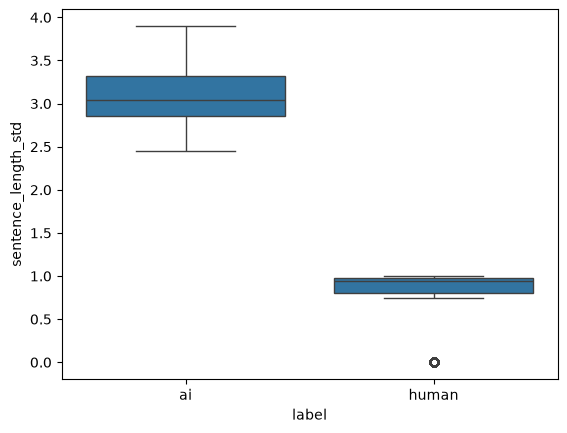

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(
    data=df_text,
    x="label",
    y="sentence_length_std"
)

plt.show()

# Boom